
# Netflix Content Intelligence: Data Analytics Case Study

**Project Type:** Data Analytics  
**Tools:** Python, Jupyter Notebook, Pandas, NumPy, Matplotlib, Seaborn  
**Dataset:** Netflix Movies and TV Shows  
**Records Analyzed:** 8,807 titles

## Problem Statement
Analyze Netflix's content catalog to understand content distribution, ratings, genres, country representation, content addition trends, and movie durations.

## Project Objectives
- Compare Movies and TV Shows.
- Analyze content ratings and popular genres.
- Explore country-wise content representation.
- Study yearly content additions.
- Analyze movie duration patterns.
- Generate data-driven business insights.

## Dataset Overview
The dataset contains 8,807 records and 12 original columns related to Netflix titles.

## Tools and Methodology
Python libraries were used for data inspection, date conversion, aggregation, statistical summaries, and visualization.

## Expected Outcome
A descriptive analytics case study with charts, key findings, business recommendations, and limitations.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

from pathlib import Path
import pandas as pd

# CSV file ka path
file_path = Path(r"C:\Users\SHASWAT SINGH\Downloads\netflix_titles_cleaned.csv")

# Dataset load karo
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Total Rows: 8807
Total Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,25-09-2021,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,24-09-2021,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,24-09-2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,24-09-2021,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,24-09-2021,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:

# 1. Dataset information
print("DATASET INFORMATION")
print("-" * 40)
df.info()

# 2. Missing values
print("\nMISSING VALUES")
print("-" * 40)
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

# 3. Duplicate records
print("\nDUPLICATE CHECK")
print("-" * 40)
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate show IDs:", df["show_id"].duplicated().sum())

# 4. Dataset size
print("\nDATASET SIZE")
print("-" * 40)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


DATASET INFORMATION
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8800 non-null   str  
 9   duration      8807 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.8 MB

MISSING VALUES
----------------------------------------
director      2634
country        831
cast           825
date_added      10
rating           7
dtype: int64

DUPLICATE CHECK
----------------------------------------

In [4]:

# Check column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Check date_added format
print("\nDATE COLUMN BEFORE CONVERSION:")
print(df["date_added"].head(10))

# Convert date_added safely
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce",
    dayfirst=True
)

# Extract useful date features
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month
df["month_name"] = df["date_added"].dt.month_name()

print("\nDATE CONVERSION COMPLETED")
print(df[["date_added", "year_added", "month_added", "month_name"]].head(10))

print("\nDataset shape:", df.shape)


COLUMN NAMES:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

DATE COLUMN BEFORE CONVERSION:
0    25-09-2021
1    24-09-2021
2    24-09-2021
3    24-09-2021
4    24-09-2021
5    24-09-2021
6    24-09-2021
7    24-09-2021
8    24-09-2021
9    24-09-2021
Name: date_added, dtype: str

DATE CONVERSION COMPLETED
  date_added  year_added  month_added month_name
0 2021-09-25      2021.0          9.0  September
1 2021-09-24      2021.0          9.0  September
2 2021-09-24      2021.0          9.0  September
3 2021-09-24      2021.0          9.0  September
4 2021-09-24      2021.0          9.0  September
5 2021-09-24      2021.0          9.0  September
6 2021-09-24      2021.0          9.0  September
7 2021-09-24      2021.0          9.0  September
8 2021-09-24      2021.0          9.0  September
9 2021-09-24      2021.0          9.0  September

Dataset shape: (8807, 15)


In [5]:

# Count Movies and TV Shows
content_counts = df["type"].value_counts()

print("CONTENT DISTRIBUTION")
print("-" * 35)
print(content_counts)

# Calculate percentages
content_percentages = (
    df["type"].value_counts(normalize=True) * 100
).round(2)

print("\nCONTENT PERCENTAGES")
print("-" * 35)
print(content_percentages)


CONTENT DISTRIBUTION
-----------------------------------
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

CONTENT PERCENTAGES
-----------------------------------
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


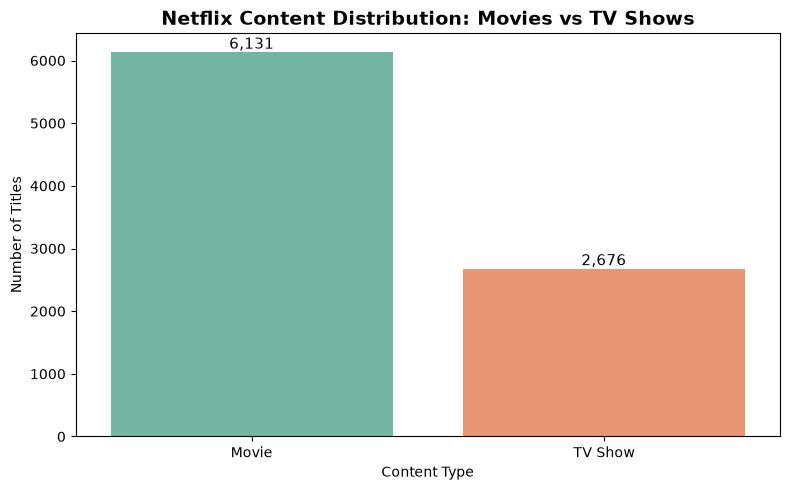

In [6]:

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="type",
    hue="type",
    order=df["type"].value_counts().index,
    palette="Set2",
    legend=False
)

plt.title("Netflix Content Distribution: Movies vs TV Shows",
          fontsize=14, fontweight="bold")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()



## 1. Movies vs. TV Shows Analysis

### Key Findings
- Total Movies: 6,131 (69.62%)
- Total TV Shows: 2,676 (30.38%)

### Business Insight
Movies account for approximately 69.62% of the titles in the dataset, while TV Shows account for 30.38%. This indicates a stronger representation of movies in the catalog. Further analysis is required to understand content trends across genres, countries, and years.


CONTENT RATING DISTRIBUTION
----------------------------------------
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


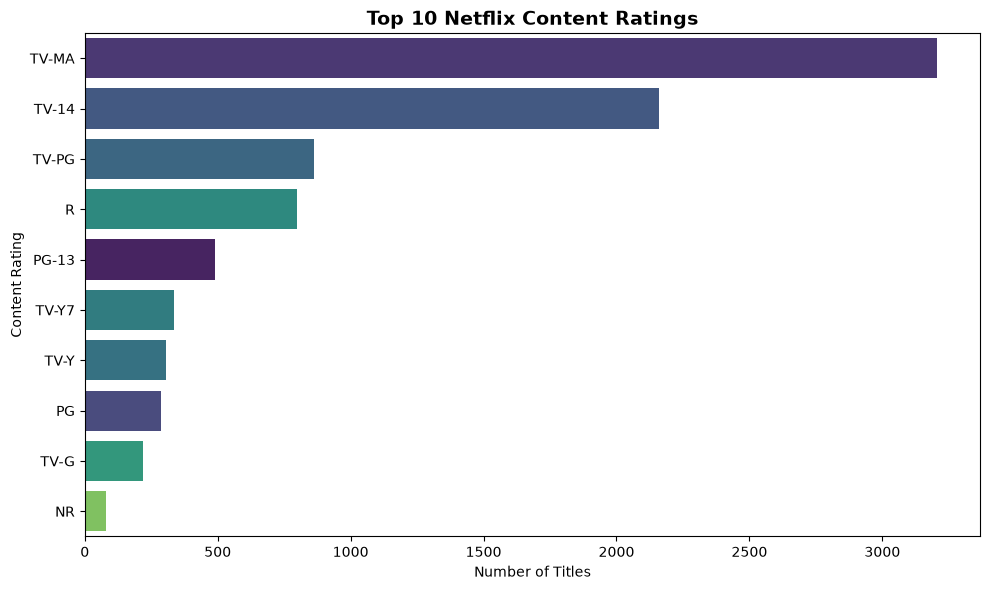

In [7]:

# Count titles by content rating
rating_counts = df["rating"].value_counts()

print("CONTENT RATING DISTRIBUTION")
print("-" * 40)
print(rating_counts)

# Plot the top 10 ratings
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    y="rating",
    order=df["rating"].value_counts().head(10).index,
    hue="rating",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Netflix Content Ratings",
          fontsize=14, fontweight="bold")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()


TOP 10 NETFLIX GENRES
-----------------------------------


,Number of Titles
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


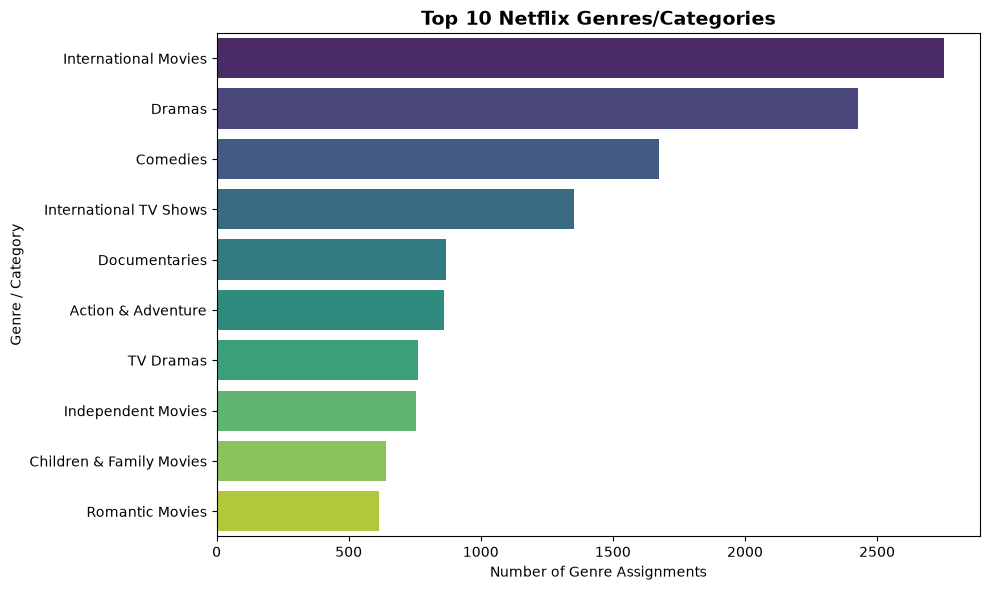

In [8]:

# Count individual genres/categories
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
)

top_genres = genre_counts.value_counts().head(10)

print("TOP 10 NETFLIX GENRES")
print("-" * 35)
display(top_genres.to_frame(name="Number of Titles"))

# Visualize top 10 genres
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    hue=top_genres.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 Netflix Genres/Categories",
          fontsize=14, fontweight="bold")
plt.xlabel("Number of Genre Assignments")
plt.ylabel("Genre / Category")
plt.tight_layout()
plt.show()


TOP 10 COUNTRIES BY TITLE COUNT
----------------------------------------


,Number of Titles
country,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


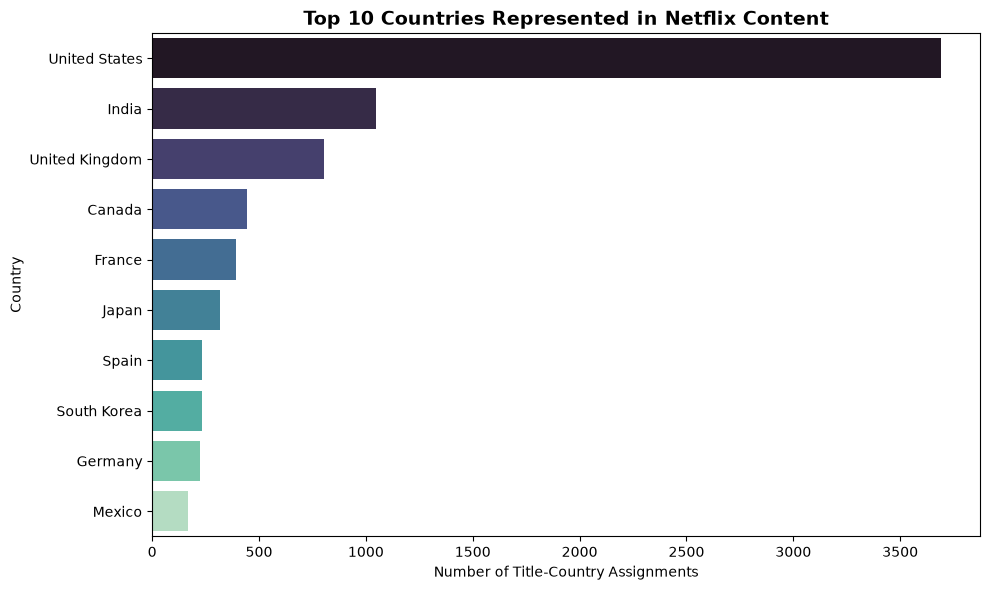

In [9]:

# Country-wise content analysis
country_counts = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
)

top_countries = country_counts.value_counts().head(10)

print("TOP 10 COUNTRIES BY TITLE COUNT")
print("-" * 40)
display(top_countries.to_frame(name="Number of Titles"))

# Create chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    hue=top_countries.index,
    palette="mako",
    legend=False
)

plt.title("Top 10 Countries Represented in Netflix Content",
          fontsize=14, fontweight="bold")
plt.xlabel("Number of Title-Country Assignments")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


MOVIE DURATION ANALYSIS
----------------------------------------
Movies with available duration: 6131
Average duration: 99.56 minutes
Median duration: 98.0 minutes
Shortest duration: 3 minutes
Longest duration: 312 minutes


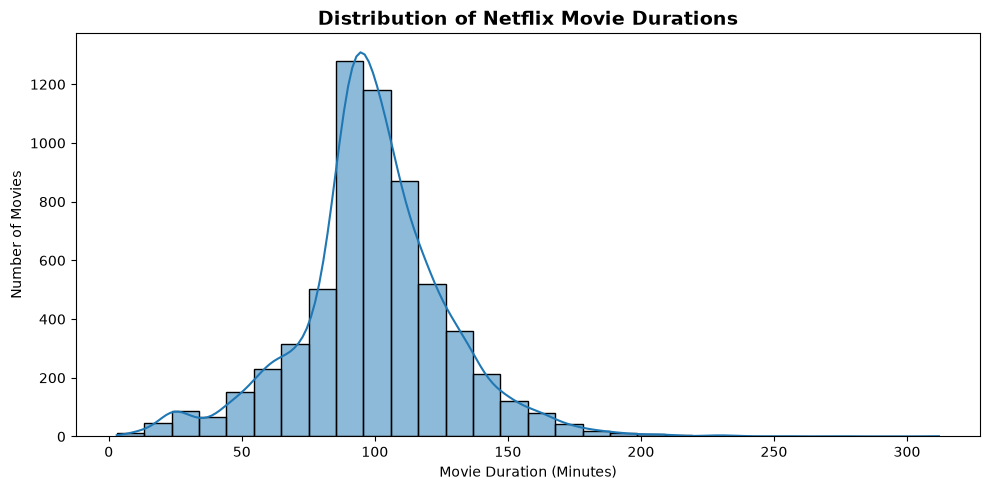

In [10]:

# Filter movies and extract duration in minutes
movies = df[df["type"] == "Movie"].copy()

movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Summary statistics
print("MOVIE DURATION ANALYSIS")
print("-" * 40)
print("Movies with available duration:",
      movies["duration_minutes"].notna().sum())
print("Average duration:",
      round(movies["duration_minutes"].mean(), 2), "minutes")
print("Median duration:",
      movies["duration_minutes"].median(), "minutes")
print("Shortest duration:",
      movies["duration_minutes"].min(), "minutes")
print("Longest duration:",
      movies["duration_minutes"].max(), "minutes")

# Visualize duration distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    movies["duration_minutes"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations",
          fontsize=14, fontweight="bold")
plt.xlabel("Movie Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()


YEAR-WISE CONTENT ADDITIONS


,Titles Added
year_added,
2008.0,2
2009.0,2
2010.0,1
2011.0,13
2012.0,3
2013.0,11
2014.0,24
2015.0,82
2016.0,429


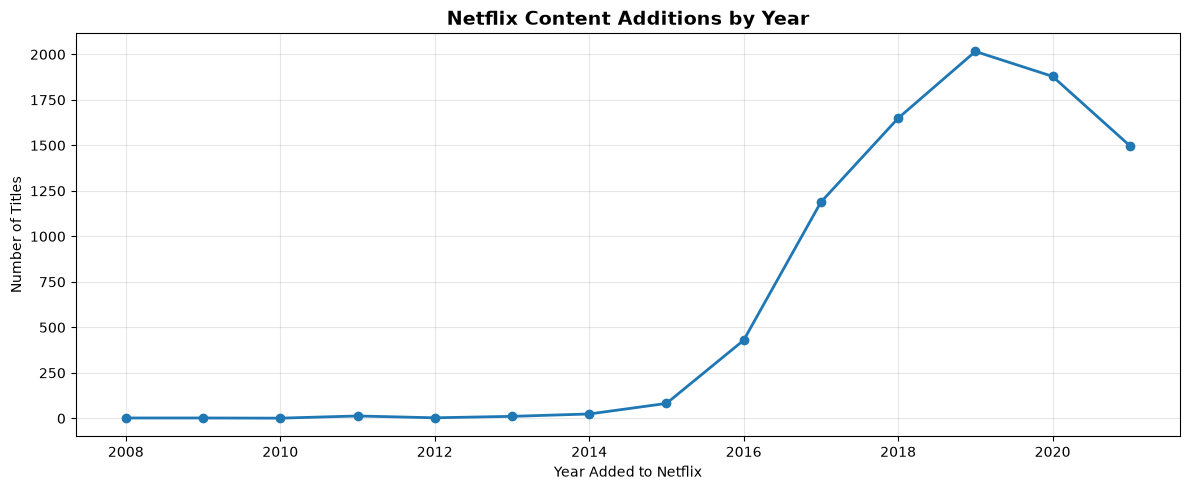

Peak year: 2019.0
Titles added: 2016


In [11]:

# Analyze titles by year added
yearly_additions = (
    df.dropna(subset=["year_added"])
      .groupby("year_added")
      .size()
      .sort_index()
)

print("YEAR-WISE CONTENT ADDITIONS")
display(yearly_additions.to_frame(name="Titles Added"))

# Visualize yearly additions
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_additions.index,
    yearly_additions.values,
    marker="o",
    linewidth=2
)

plt.title("Netflix Content Additions by Year",
          fontsize=14, fontweight="bold")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Find peak year
if not yearly_additions.empty:
    print("Peak year:", yearly_additions.idxmax())
    print("Titles added:", yearly_additions.max())


In [12]:

# Top countries by number of associated titles
country_counts = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
)

top_countries = country_counts.value_counts().head(10)

print("TOP 10 COUNTRIES")
display(top_countries.to_frame(name="Title-Country Count"))

# Highlight the leading country
print("Top country:", top_countries.index[0])
print("Associated title count:", top_countries.iloc[0])


TOP 10 COUNTRIES


,Title-Country Count
country,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


Top country: United States
Associated title count: 3689



## 7. Interactive Dashboard

An interactive Netflix Content Intelligence Dashboard was developed as part of SWYNEX Technologies Task 3. The dashboard helps users explore Netflix Movies and TV Shows data through interactive filters and visualizations.

**Live Dashboard:** [Open Netflix Content Intelligence Dashboard](https://shaswatsingh-analytics.github.io/SWYNEX-Interactive-Dashboard/Netflix_Content_Intelligence_Dashboard.html)

### Dashboard Features
- Movies vs. TV Shows distribution
- Content added over time
- Content distribution by release year
- Top 10 genres and countries
- Content rating distribution
- Movies vs. TV Shows by release year
- Interactive filters for content type, release year, rating, and country
- Key insights that update based on the selected filters

### Tools and Technologies
HTML, CSS, JavaScript, SVG visualizations, and the cleaned Netflix titles dataset.

### Purpose
The dashboard presents the analysis in an interactive and accessible format, allowing users to explore content patterns and understand the dataset's key characteristics.

**Note:** The dashboard represents historical data from the supplied dataset and does not show Netflix's live catalog availability.



## Data Cleaning and Preparation

The Netflix dataset was inspected using Pandas to understand its structure, missing values, duplicate records, and data types.

### Data Quality Checks
- Checked the dataset dimensions and column names.
- Identified missing values in director, cast, country, date_added, and rating.
- Checked for exact duplicate rows and duplicate show IDs.
- Converted the date_added column to datetime format.
- Extracted year_added, month_added, and month_name for time-based analysis.

### Missing Value Handling
Missing values were retained where appropriate rather than automatically deleting records. Date values that could not be parsed were treated as missing for the date-based analysis.

### Preparation Outcome
The dataset was prepared for descriptive analysis of content types, ratings, genres, countries, yearly additions, and movie durations.


## Final Business Insights

Based on the exploratory data analysis of the Netflix titles dataset, the following key insights were identified:

1. **Content Library:** The dataset contains 8,807 titles, including movies and TV shows, providing a broad view of Netflix's content catalogue.

2. **Content Ratings:** TV-MA is the most frequent content rating, followed by TV-14 and TV-PG. This indicates a substantial representation of mature and teen-oriented content in the catalogue.

3. **Popular Categories:** International Movies, Dramas, and Comedies are among the most frequently listed genres or categories. These categories represent important areas of content availability.

4. **Country Representation:** The United States has the highest number of associated titles in the country analysis, followed by India and the United Kingdom. International production is also represented in the catalogue.

5. **Movie Duration:** The average movie duration is approximately 99.56 minutes, while the median is 98 minutes. Most movies in the analysis are concentrated around the 90–120 minute range.

6. **Content Addition Trends:** The dataset shows that 2019 had the highest number of titles added to Netflix among the years represented in the analysis. The number of additions declined in 2020 and 2021.

---

## Business Recommendations

1. **Review Content Mix:** Netflix could regularly evaluate its movie and TV show catalogue by rating, genre, and country to understand the distribution of available content.

2. **Support International Content Analysis:** The strong representation of international titles suggests that country-level and genre-level analysis may help identify areas for further content research.

3. **Use Genre Trends for Planning:** Content teams could examine genre distributions alongside audience viewing and engagement data before making content acquisition or production decisions.

4. **Monitor Catalogue Changes:** Tracking titles added over time can help analysts understand catalogue growth and identify periods of increased or reduced content additions.

5. **Improve Future Analysis:** Combining catalogue data with viewership, completion rates, audience preferences, and content costs could support more informed business decisions.

> **Note:** These are analytical recommendations based on catalogue patterns. The dataset alone does not establish audience demand, profitability, or the causes of changes in content additions.

---

## Project Limitations

1. The dataset represents catalogue information and does not include actual viewership, watch time, customer satisfaction, or revenue data.

2. Some fields contain missing values, including director, cast, country, date added, and rating. These missing values may limit certain analyses.

3. A title may be associated with multiple countries or genres. Therefore, country and genre counts may represent title associations rather than mutually exclusive categories.

4. The year a title was added to Netflix is different from its original release year. These fields should not be interpreted as interchangeable.

5. The analysis describes patterns in the available dataset and does not establish causal relationships or predict future content performance.

6. The findings are based on the dataset used in this project and may not represent Netflix's current catalogue.

---

## Conclusion

This project applied Python-based data analysis to explore Netflix's content catalogue. The analysis examined content ratings, genres, country representation, movie durations, and yearly content additions using tables and visualisations. The findings provide a structured overview of the catalogue and demonstrate how exploratory data analysis can help identify patterns in business data.

The interactive Netflix Content Intelligence Dashboard complements the notebook by allowing users to explore the catalogue visually.

**Dashboard:** [Netflix Content Intelligence Dashboard](https://shaswatsingh-analytics.github.io/SWYNEX-Interactive-Dashboard/Netflix_Content_Intelligence_Dashboard.html)

The project demonstrates a practical workflow involving dataset inspection, data cleaning, exploratory analysis, visualisation, and business-oriented interpretation. Further analysis incorporating viewership, engagement, and financial data would be needed to evaluate content performance and business outcomes.